In [1]:
from pathlib import Path
import nibabel as nib
import numpy as np
from numpy.typing import NDArray
from scipy.interpolate import BSpline, make_lsq_spline
from skimage import filters, segmentation
from scipy import ndimage
import matplotlib.pyplot as plt

nii = (
    "data/ABCD_QA_fMRI_16.nii.gz",
    "data/FBIRN_QA_fMRI_flip77_13.nii.gz",
    "data/FBIRN_QA_fMRI_flip77_14.nii.gz",
)

img = nib.load(nii[1])
data = img.get_fdata()  # numpy array, shape e.g. (X, Y, Z)
tr = img.header.get_zooms()[3]
dx = img.header.get_zooms()[0]

def trim_initial(data, tr, trim_sec):
    n = max(int(round(trim_sec / tr)), 0)
    return data[..., n:]

def segment_phantom(image):
    edges = filters.sobel(image, mode="wrap")
    labels = np.zeros_like(image, dtype=np.uint8)
    labels[image < np.quantile(image, 0.1)] = 1
    labels[image > np.quantile(image, 0.9)] = 2
    return segmentation.watershed(edges, labels) == 2

def extract_center_slice(data):
    mip = data.max(axis=-1)
    mask_size = [segment_phantom(i).sum() for i in np.moveaxis(mip, -1, 0)]
    center =  np.argmax(mask_size)
    return data[:,:,center,:]

def find_phantom_center(phantom_mask):    
    dist = ndimage.distance_transform_edt(phantom_mask)
    center = np.unravel_index(np.argmax(dist), dist.shape)
    return np.array(center)

def roi_indexes(center, n):
    p1 = center - (n-1)//2
    p2 = p1 + n
    return slice(p1[1], p2[1]), slice(p1[0], p2[0])

def largest_roi(phantom_mask, center):
    for n in range(1, 64, 2):
        roi = roi_indexes(center, n)
        if ~np.all(phantom_mask[roi]):
            return n-1

def roi_timeseries(data, center, n):
    roi = roi_indexes(center, n)
    return data[*roi,:].mean(axis=(0,1))

def spline_fit(
    y: NDArray[np.float64],
    tr: float,
    cutoff_s: float = 256.0,
    degree: int = 2,
) -> tuple[NDArray[np.float64], BSpline]:
    n = y.shape[0]
    x = np.arange(n, dtype=np.float64)

    # knots every `cutoff_s` seconds, over the fitted (steady-state) span only
    n_interior = max(int(round(n * tr / cutoff_s)) - 1, 0)
    t = np.concatenate((
        np.full(degree + 1, 0),
        np.linspace(0, n, n_interior + 2)[1:-1],
        np.full(degree + 1, n),
    ))
    spl = make_lsq_spline(x, y, t, k=degree)
    return spl(x)

def poly_degree(y, tr, cutoff_s=200.0):
    n = y.shape[-1]
    return int(np.round(n * tr / cutoff_s))

def poly_residuals(y, degree):
    nt = y.shape[-1]
    x = np.linspace(-1.0, 1.0, nt, dtype=float)

    # Design matrix: (nt, degree + 1)
    design = np.polynomial.legendre.legvander(x, degree)

    # Treat all leading-index combinations as separate signals.
    signals = y.reshape(-1, nt).T

    # coefficients: (degree + 1, number_of_signals)
    coefficients, *_ = np.linalg.lstsq(design, signals, rcond=None)

    fitted = (design @ coefficients).T
    return y - fitted.reshape(y.shape)

2


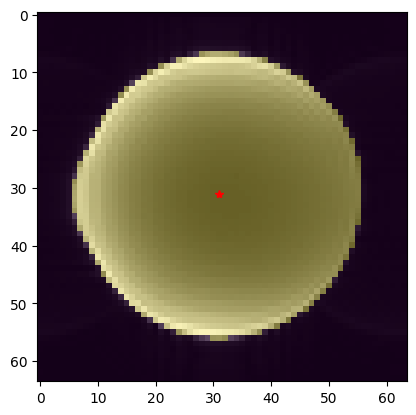

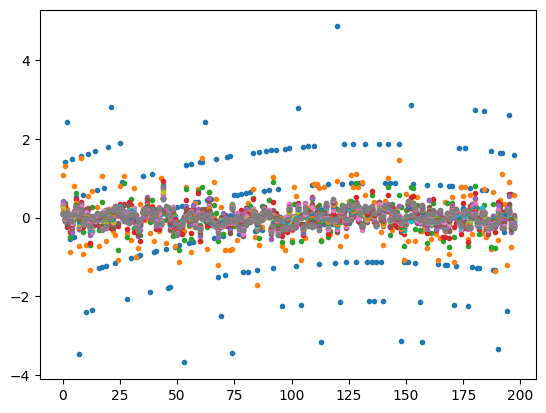

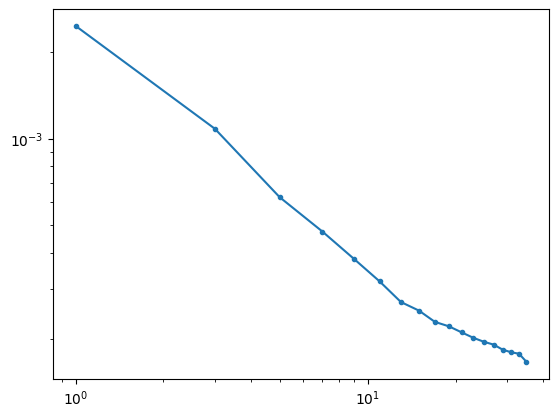

In [2]:
data = trim_initial(data, tr, 5.0)
center_slice = extract_center_slice(data)
phantom_mask = segment_phantom(center_slice.max(axis=-1))
center = find_phantom_center(phantom_mask)
degree = poly_degree(center_slice, tr)
fluctuations = poly_residuals(center_slice, degree)
k_max = largest_roi(phantom_mask, center)

plt.imshow(center_slice.max(axis=-1), "gray")
plt.imshow(phantom_mask, alpha=0.3)
plt.plot(*center[::-1], 'r*')

plt.figure()

r = range(1, k_max, 2)
cv = []
print(degree)
for i in r:
    t = roi_timeseries(center_slice, center, i)
    res = poly_residuals(t, degree)
    plt.plot(res, '.')
    cv.append(np.std(res, mean=0)/t.mean())

plt.figure()
plt.loglog(r, cv, '.-')

/tmp/ipykernel_869990/3738344777.py:7: RuntimeWarning: divide by zero encountered in log
  plt.imshow(np.log(fluct_noise), "gray")


np.float64(10574.081842067377)

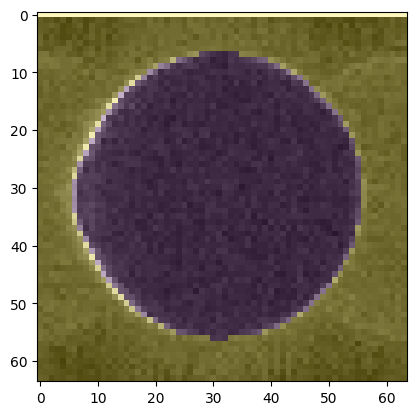

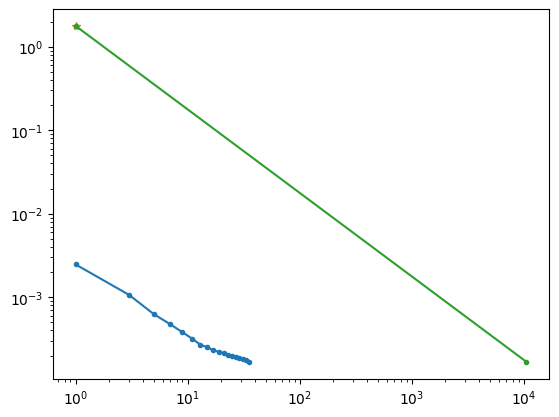

In [5]:
import numpy as np

res = poly_residuals(center_slice, degree)

mean_image = np.mean(center_slice, axis=-1)
fluct_noise = np.std(res, axis=-1, mean=0)
plt.imshow(np.log(fluct_noise), "gray")
plt.imshow(~phantom_mask, alpha=0.3)

roi = roi_indexes(center, k_max)

s = fluct_noise[phantom_mask]
mu = mean_image[*roi]

cv1_pooled = float(np.sqrt(np.mean(s**2))) # RMS(s) / mean(mu)

cv1_pooled
rdc = cv1_pooled / cv[-1]

plt.figure()
plt.loglog(r, cv, '.-')
plt.loglog(1, cv1_pooled, '*')
plt.loglog((1,rdc), (cv1_pooled, cv[-1]), '.-')

rdc

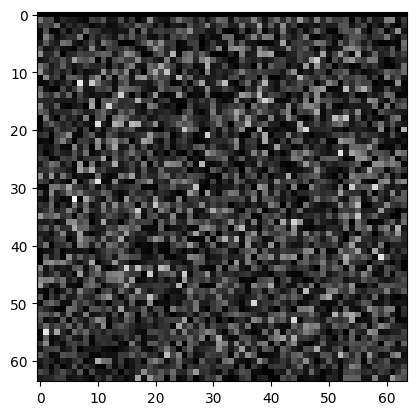

In [12]:
plt.imshow(np.abs(center_slice[..., 0::2].mean(axis=-1) - center_slice[..., 1::2].mean(axis=-1)), "gray")

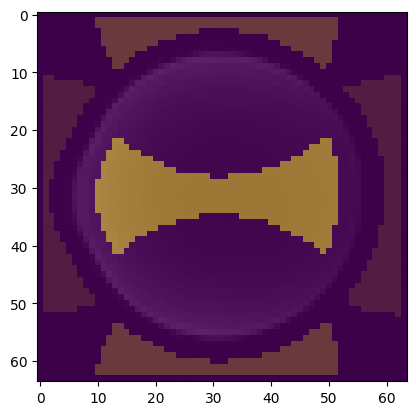

In [13]:
from skimage import morphology

pe_axis=0
phantom = phantom_mask
canvas = np.ones_like(phantom)
canvas[(0,-1),:] = 0
canvas[:,(0,-1)] = 0
ghost_pe = np.roll(phantom, phantom.shape[pe_axis]//2, axis=pe_axis)
ghost_ro = np.roll(phantom, phantom.shape[1-pe_axis]//2, axis=1-pe_axis)

def some_function(signal, ghost):
    mask = morphology.isotropic_erosion(signal, 4) & ~morphology.isotropic_dilation(ghost, 4) & canvas
    return mask
    
    
plt.imshow(center_slice.max(axis=-1), "gray")
plt.imshow(some_function(ghost_ro, phantom), alpha=0.5)
plt.imshow(some_function(ghost_pe, phantom), alpha=0.5)
plt.imshow(some_function(phantom, ghost_pe), alpha=0.5)

In [14]:
phantom.shape[pe_axis]

64